# Notebook 05: Sentiment classifiers

Task: predict *negative / neutral / positive* from review text, using star ratings as distant supervision
(1-2-star negative, 3-star neutral, 4-5-star positive). The trained classifier later scores each aspect's opinion scope
(notebooks 06-07).

Design
* 5 text representations and 3 classical classifiers = 15 models, each tuned by 5-fold cross-validation on the training
  subset only. The test sets are never used for any choice.
* Headline metric: macro-F1 (the neutral class is only 7% of the data; accuracy would hide failure on it).
* Every score has a 95% bootstrap confidence interval; model differences are tested with McNemar's test.
* Three test sets: holdout (same apps), test_known (EcoCash Super App), test_unseen (four new brands).

In [1]:
# Setup
import sys, warnings
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from absa.setup import ensure_resources
from absa import viz
ensure_resources()
viz.use_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

In [2]:
import time, json, joblib
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from absa.config import SEED, LABELS, TABLES_DIR, MODELS_DIR
from absa.data import load_reviews
from absa.models import (FEATURES, FEATURE_NAMES, CLASSIFIER_NAMES, make_pipeline_for,
                         param_grid, top_features)
from absa.evaluate import scores, score_table, bootstrap_ci, mcnemar, confusion
from absa.baselines import vader_label, transformer_predictions

reviews = load_reviews()
SUBSETS = {"holdout": "In-domain (holdout)", "test_known": "Known brand, new app",
           "test_unseen": "Unseen brands"}
train = reviews[reviews["subset"] == "train"]
tests = {s: reviews[reviews["subset"] == s] for s in SUBSETS}
print(f"train: {len(train)} reviews  |  " + "  |  ".join(f"{s}: {len(d)}" for s, d in tests.items()))
train["label"].value_counts(normalize=True).round(3)

train: 3197 reviews  |  holdout: 800  |  test_known: 1195  |  test_unseen: 1014


label
positive    0.650
negative    0.280
neutral     0.071
Name: proportion, dtype: float64

## 1. Model selection by cross-validation (training data only)

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results, fitted = [], {}
for feat in FEATURES:
    for clf in CLASSIFIER_NAMES:
        t0 = time.time()
        gs = GridSearchCV(make_pipeline_for(feat, clf), param_grid(feat, clf),
                          scoring="f1_macro", cv=cv, n_jobs=-1)
        gs.fit(train["clean"], train["label"])
        best = gs.best_index_
        results.append({"features": feat, "classifier": clf,
                        "cv_macro_f1": gs.cv_results_["mean_test_score"][best],
                        "cv_std": gs.cv_results_["std_test_score"][best],
                        "best_params": json.dumps(gs.best_params_),
                        "seconds": round(time.time() - t0, 1)})
        fitted[(feat, clf)] = gs.best_estimator_
grid = pd.DataFrame(results).sort_values("cv_macro_f1", ascending=False)
grid.to_csv(TABLES_DIR / "05_cv_grid.csv", index=False)
grid.round(4)

,features,classifier,cv_macro_f1,cv_std,best_params,seconds
10,tfidf_word_char,svm,0.6381,0.0376,"{""clf__C"": 0.3}",5.1
7,tfidf_char,svm,0.6353,0.0347,"{""clf__C"": 0.1}",3.6
11,tfidf_word_char,logreg,0.6330,0.0155,"{""clf__C"": 0.3}",7.6
8,tfidf_char,logreg,0.6319,0.0174,"{""clf__C"": 3.0}",6.0
5,tfidf_word,logreg,0.6236,0.0143,"{""clf__C"": 1.0}",1.6
2,bow,logreg,0.6222,0.0342,"{""clf__C"": 0.3}",1.8
4,tfidf_word,svm,0.6216,0.0370,"{""clf__C"": 0.3}",1.0
13,fasttext,svm,0.6214,0.0131,"{""clf__C"": 0.1}",4.8
1,bow,svm,0.6117,0.0323,"{""clf__C"": 0.3}",1.1
14,fasttext,logreg,0.6033,0.0169,"{""clf__C"": 0.3}",3.3


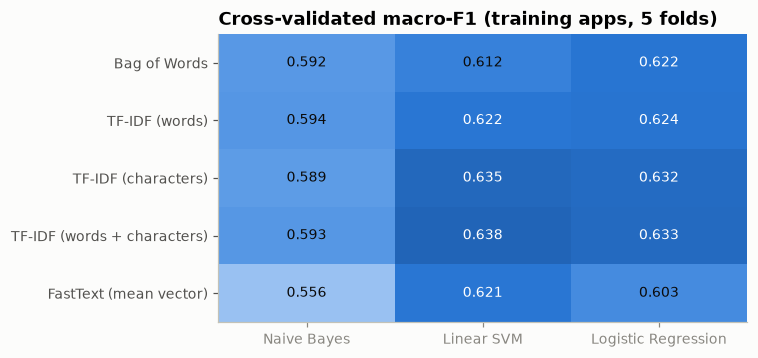

In [4]:
heat = grid.pivot(index="features", columns="classifier", values="cv_macro_f1").loc[list(FEATURES), list(CLASSIFIER_NAMES)]
fig, ax = plt.subplots(figsize=(6.2, 3.4))
im = ax.imshow(heat.values, cmap=viz.SEQUENTIAL, vmin=0.5, vmax=0.66, aspect="auto")
ax.set_xticks(range(3), [CLASSIFIER_NAMES[c] for c in heat.columns])
ax.set_yticks(range(len(heat)), [FEATURE_NAMES[f] for f in heat.index])
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.62 else viz.INK)
ax.grid(False)
ax.set_title("Cross-validated macro-F1 (training apps, 5 folds)")
viz.save(fig, "05_cv_heatmap")
plt.show()

### Choosing the final model: the one-standard-error rule
The top models are within noise of each other. The rule: take the best CV score, then prefer the simplest / most
useful model whose score is within one standard error of it. Logistic regression is preferred when eligible
because it outputs probabilities, which the interface shows as confidence, and its weights are directly readable.

In [5]:
top = grid.iloc[0]
se = top["cv_std"] / np.sqrt(cv.get_n_splits())
eligible = grid[grid["cv_macro_f1"] >= top["cv_macro_f1"] - se]
choice = eligible[eligible["classifier"] == "logreg"].head(1)
choice = choice if len(choice) else eligible.head(1)
BEST = (choice["features"].iloc[0], choice["classifier"].iloc[0])
best_params = json.loads(choice["best_params"].iloc[0])
print(f"best CV: {top['features']} + {top['classifier']} = {top['cv_macro_f1']:.4f} (SE {se:.4f})")
print(f"eligible within 1 SE:\n{eligible[['features', 'classifier', 'cv_macro_f1']].round(4).to_string(index=False)}")
print(f"\nCHOSEN: {FEATURE_NAMES[BEST[0]]} + {CLASSIFIER_NAMES[BEST[1]]}, {best_params}")
model = fitted[BEST]

best CV: tfidf_word_char + svm = 0.6381 (SE 0.0168)
eligible within 1 SE:
       features classifier  cv_macro_f1
tfidf_word_char        svm       0.6381
     tfidf_char        svm       0.6353
tfidf_word_char     logreg       0.6330
     tfidf_char     logreg       0.6319
     tfidf_word     logreg       0.6236
            bow     logreg       0.6222
     tfidf_word        svm       0.6216
       fasttext        svm       0.6214

CHOSEN: TF-IDF (words + characters) + Logistic Regression, {'clf__C': 0.3}


## 2. Test-set results

In [6]:
# all 15 models on the test sets (not used for selection)
rows = []
for (feat, clf), m in fitted.items():
    row = {"features": FEATURE_NAMES[feat], "classifier": CLASSIFIER_NAMES[clf]}
    for s, d in tests.items():
        row[SUBSETS[s]] = scores(d["label"], m.predict(d["clean"]))["macro_f1"]
    rows.append(row)
all_models = pd.DataFrame(rows).sort_values(SUBSETS["holdout"], ascending=False)
all_models.to_csv(TABLES_DIR / "05_all_models_test.csv", index=False)
all_models.round(3)

,features,classifier,In-domain (holdout),"Known brand, new app",Unseen brands
1,Bag of Words,Linear SVM,0.640,0.625,0.591
10,TF-IDF (words + characters),Linear SVM,0.639,0.632,0.601
8,TF-IDF (characters),Logistic Regression,0.638,0.624,0.607
2,Bag of Words,Logistic Regression,0.636,0.621,0.629
11,TF-IDF (words + characters),Logistic Regression,0.632,0.642,0.632
7,TF-IDF (characters),Linear SVM,0.626,0.634,0.614
5,TF-IDF (words),Logistic Regression,0.614,0.636,0.621
14,FastText (mean vector),Logistic Regression,0.609,0.592,0.622
4,TF-IDF (words),Linear SVM,0.598,0.636,0.611
3,TF-IDF (words),Naive Bayes,0.594,0.603,0.629


In [7]:
# baselines
reviews["pred"] = model.predict(reviews["clean"])
reviews["vader"] = reviews["content"].map(vader_label)
reviews["majority"] = train["label"].mode()[0]
tf = transformer_predictions()
if tf is not None:
    reviews = reviews.merge(tf.rename(columns={"key": "reviewId", "pred": "transformer"})[["reviewId", "transformer"]],
                            on="reviewId", how="left")
    print("transformer predictions found")
else:
    print("transformer predictions not found: run scripts/transformer_baseline.py to add them")

model_cols = {"pred": "Our model", "vader": "VADER", "majority": "Majority class"}
if "transformer" in reviews:
    model_cols["transformer"] = "Twitter-RoBERTa (transformer)"

main = []
for s, name in SUBSETS.items():
    d = reviews[reviews["subset"] == s]
    t = score_table(d["label"], {v: d[k] for k, v in model_cols.items() if d[k].notna().all()})
    t.insert(0, "test set", name)
    main.append(t)
main = pd.concat(main)
main.to_csv(TABLES_DIR / "05_main_results.csv")
main.round(3)

transformer predictions found


,test set,n,accuracy,macro_precision,macro_recall,macro_f1,macro_f1_ci,f1_negative,f1_neutral,f1_positive
model,,,,,,,,,,
Our model,In-domain (holdout),800,0.776,0.623,0.664,0.632,"[0.596, 0.673]",0.752,0.270,0.873
VADER,In-domain (holdout),800,0.664,0.548,0.476,0.488,"[0.457, 0.519]",0.553,0.096,0.815
Majority class,In-domain (holdout),800,0.650,0.217,0.333,0.263,"[0.254, 0.271]",0.000,0.000,0.788
Twitter-RoBERTa (transformer),In-domain (holdout),800,0.794,0.626,0.636,0.623,"[0.591, 0.656]",0.809,0.171,0.890
Our model,"Known brand, new app",1195,0.845,0.626,0.699,0.642,"[0.606, 0.678]",0.795,0.213,0.916
VADER,"Known brand, new app",1195,0.722,0.575,0.507,0.496,"[0.467, 0.526]",0.544,0.082,0.861
Majority class,"Known brand, new app",1195,0.754,0.251,0.333,0.287,"[0.282, 0.292]",0.000,0.000,0.860
Twitter-RoBERTa (transformer),"Known brand, new app",1195,0.826,0.617,0.629,0.604,"[0.579, 0.630]",0.790,0.103,0.919
Our model,Unseen brands,1014,0.779,0.638,0.653,0.632,"[0.603, 0.666]",0.836,0.231,0.830


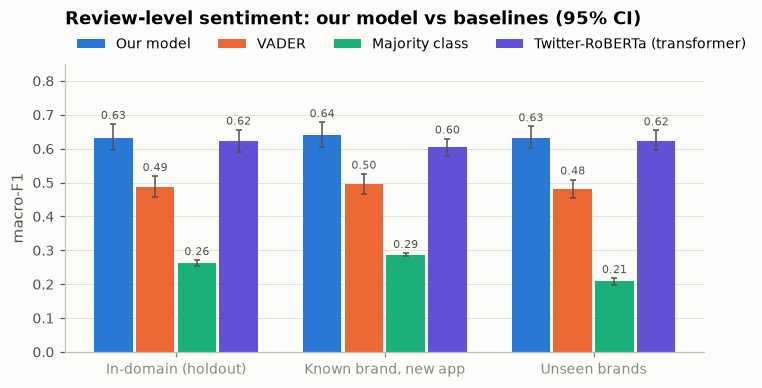

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
names = list(model_cols.values())
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]
width = 0.8 / len(names)
for k, name in enumerate(names):
    vals, los, his = [], [], []
    for s in SUBSETS:
        row = main[(main["test set"] == SUBSETS[s])].loc[name] if name in main[(main["test set"] == SUBSETS[s])].index else None
        if row is None:
            vals.append(np.nan); los.append(0); his.append(0); continue
        lo, hi = [float(x) for x in row["macro_f1_ci"].strip("[]").split(",")]
        vals.append(row["macro_f1"]); los.append(row["macro_f1"] - lo); his.append(hi - row["macro_f1"])
    x = np.arange(len(SUBSETS)) + (k - (len(names) - 1) / 2) * width
    ax.bar(x, vals, width * 0.92, color=palette[k], label=name)
    ax.errorbar(x, vals, yerr=[los, his], fmt="none", ecolor=viz.INK_2, elinewidth=1, capsize=2)
    for xi, v, h in zip(x, vals, his):
        hi_ = v + h
        if not np.isnan(v):
            ax.text(xi, hi_ + 0.015, f"{v:.2f}", ha="center", fontsize=7.5, color=viz.INK_2)
ax.set_xticks(range(len(SUBSETS)), list(SUBSETS.values()))
ax.set_ylim(0, 0.85); ax.set_ylabel("macro-F1"); ax.grid(axis="x", visible=False)
ax.legend(ncol=len(names), loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Review-level sentiment: our model vs baselines (95% CI)", pad=26)
viz.save(fig, "05_main_results")
plt.show()

In [9]:
# McNemar: our model vs VADER
pd.DataFrame({SUBSETS[s]: mcnemar(d["label"], d["pred"], d["vader"])
              for s, d in reviews.groupby("subset") if s in SUBSETS}).T

,only_a_correct,only_b_correct,p_value
In-domain (holdout),173.0,83.0,1.918004e-08
"Known brand, new app",237.0,90.0,2.095800e-16
Unseen brands,294.0,93.0,2.102180e-25


In [10]:
# McNemar: our model vs transformer
if "transformer" in reviews:
    display(pd.DataFrame({SUBSETS[s]: mcnemar(d["label"], d["pred"], d["transformer"])
                          for s, d in reviews.groupby("subset") if s in SUBSETS}).T)

,only_a_correct,only_b_correct,p_value
In-domain (holdout),64.0,78.0,0.275250
"Known brand, new app",119.0,96.0,0.133326
Unseen brands,109.0,98.0,0.487117


Reading the results
* The trained model beats VADER on every test set by roughly 14-15 macro-F1 points, and McNemar's test shows the
  difference is far beyond chance. A general-purpose lexicon does not know *otp*, *not opening* or *chakadhakwa*.
* Generalisation: there is virtually no drop from familiar apps to unseen brands (0.632 on both, with
  overlapping CIs), even though the unseen brands are far more negative. The proposal's claim that the sentiment
  component is *not tied to any one app* is supported.
* The pretrained transformer (Twitter-RoBERTa, used zero-shot: never trained on these reviews) comes close at
  0.60-0.62. Our model is numerically ahead on all three sets, but McNemar's test finds no significant difference
  (p = 0.13-0.49). A 1 MB model trained in seconds on 3,200 local reviews matches a 500 MB model trained on ~124 million
  tweets, and it runs on any laptop without PyTorch.
* The known-brand test (Super App) scores about the same as the holdout, as predicted: shared EcoCash vocabulary
  makes it the easier out-of-domain test, which is why it is reported separately.

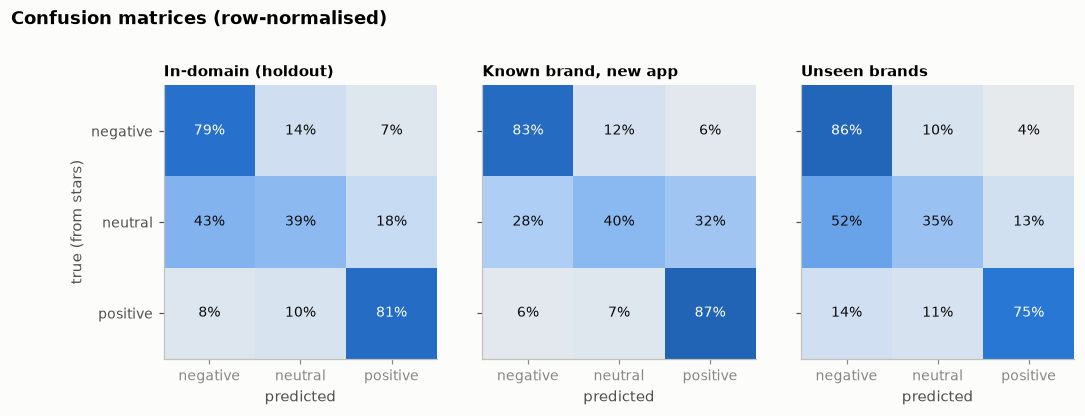

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, (s, name) in zip(axes, SUBSETS.items()):
    d = reviews[reviews["subset"] == s]
    cm = confusion(d["label"], d["pred"], normalize=True)
    ax.imshow(cm.values, cmap=viz.SEQUENTIAL, vmin=0, vmax=1)
    ax.set_xticks(range(3), LABELS, rotation=0); ax.set_yticks(range(3), LABELS)
    ax.tick_params(axis="y", labelleft=(ax is axes[0]))
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm.values[i, j]:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if cm.values[i, j] > 0.55 else viz.INK)
    ax.set_title(name, fontsize=10); ax.set_xlabel("predicted"); ax.grid(False)
axes[0].set_ylabel("true (from stars)")
fig.suptitle("Confusion matrices (row-normalised)", x=0.01, y=0.99, ha="left", fontweight="bold")
fig.subplots_adjust(top=0.80, wspace=0.06)
viz.save(fig, "05_confusion")
plt.show()

The neutral row is where the model struggles: most 3-star reviews are predicted negative or positive. Reading them
explains why: 3-star reviews are usually mixed ("Improved functionality but I need proof of payment...") or complaints
with a polite rating, not neutral statements. At review level, "neutral" is a weak, noisy category. This is the strongest
argument for analysing aspects instead of whole reviews.

## 3. Short vs long reviews, and the neutral class

In [12]:
rows = []
for s, name in SUBSETS.items():
    d = reviews[reviews["subset"] == s]
    for short, g in d.groupby("is_short"):
        rows.append({"test set": name, "reviews": "3 words or fewer" if short else "> 3 words", "n": len(g),
                     **{k: v for k, v in scores(g["label"], g["pred"]).items() if k in ("accuracy", "macro_f1")}})
pd.DataFrame(rows).pivot(index="test set", columns="reviews", values=["n", "accuracy", "macro_f1"]).round(3)

n                   accuracy                   macro_f1          
reviews              3 words or fewer > 3 words 3 words or fewer > 3 words 3 words or fewer > 3 words
test set                                                                                             
In-domain (holdout)             331.0     469.0            0.885     0.699            0.555     0.610
Known brand, new app            538.0     657.0            0.907     0.795            0.532     0.649
Unseen brands                   323.0     691.0            0.836     0.753            0.632     0.600

In [13]:
# (a) class weights on vs off   (b) binary task without neutral
feat, clf = BEST
rows = []
for balanced in (True, False):
    m = make_pipeline_for(feat, clf, balanced=balanced).set_params(**best_params).fit(train["clean"], train["label"])
    for s, name in SUBSETS.items():
        d = tests[s]; sc = scores(d["label"], m.predict(d["clean"]))
        rows.append({"setting": "3 classes, balanced weights" if balanced else "3 classes, no weights",
                     "test set": name, "macro_f1": sc["macro_f1"], "f1_neutral": sc["f1_neutral"],
                     "recall_neutral": sc["recall_neutral"]})
tb = train[train["label"] != "neutral"]
mb = make_pipeline_for(feat, clf).set_params(**best_params).fit(tb["clean"], tb["label"])
for s, name in SUBSETS.items():
    d = tests[s][tests[s]["label"] != "neutral"]
    sc = scores(d["label"], mb.predict(d["clean"]), labels=["negative", "positive"])
    rows.append({"setting": "2 classes (neutral removed)", "test set": name, "macro_f1": sc["macro_f1"],
                 "f1_neutral": np.nan, "recall_neutral": np.nan, "accuracy": sc["accuracy"]})
neutral = pd.DataFrame(rows)
neutral.to_csv(TABLES_DIR / "05_neutral_handling.csv", index=False)
neutral.pivot(index="setting", columns="test set", values="macro_f1").round(3)

test set,In-domain (holdout),"Known brand, new app",Unseen brands
setting,,,
2 classes (neutral removed),0.861,0.874,0.875
"3 classes, balanced weights",0.632,0.642,0.632
"3 classes, no weights",0.558,0.578,0.562


* Without class weights the model almost never predicts *neutral*. Balanced weights trade a little accuracy for a
  real neutral recall, which is why they are used.
* With neutral removed, the task becomes much easier (macro-F1 about 0.88). The hard part of review-level sentiment
  in this corpus is not polarity but the mixed 3-star reviews.
* Long reviews score higher than short ones on the two EcoCash/training-brand test sets (short reviews such as "Cool"
  or "Not open" carry little evidence and much of the label noise). On the unseen brands the order flips, because
  their long reviews are more often mixed complaints.

## 4. Ablation study: what does each preprocessing step contribute?

The chosen model is retrained with one step changed at a time. Cross-validated macro-F1 on the training data is
the main column (five folds, so less noisy than one test set); test scores are shown for completeness.

In [14]:
from absa.text import clean, lemmatize, tokenize, remove_stopwords, stopwords
naive_sw = set(stopwords()) | {"not", "no", "nor", "never", "but", "cannot", "very", "too", "only"}

variants = {
    "full pipeline (chosen)":            lambda t: clean(t),
    "no cleaning (lowercase only)":      lambda t: t.lower() if isinstance(t, str) else "",
    "no contraction expansion (rule 3)": lambda t: clean(t, contractions=False),
    "no text-speak normalisation (4-6)": lambda t: clean(t, slang=False),
    "no brand masking (rule 7)":         lambda t: clean(t, mask_brands=False),
    "no emoji conversion":               lambda t: clean(t, emojis=False),
    "no local-language glossary (rule 12)": lambda t: clean(t, local=False),
    "+ standard stopword removal":       lambda t: " ".join(t2 for t2 in tokenize(clean(t)) if t2 not in naive_sw),
    "+ negation-safe stopword removal":  lambda t: " ".join(remove_stopwords(tokenize(clean(t)))),
}
texts = {name: reviews["content"].map(f) for name, f in variants.items()}
texts["+ lemmatisation (spaCy)"] = pd.Series(lemmatize(reviews["clean"].tolist()), index=reviews.index)

rows = []
for name, txt in texts.items():
    m = make_pipeline_for(*BEST).set_params(**best_params)
    cvs = cross_val_score(m, txt[train.index], train["label"], cv=cv, scoring="f1_macro", n_jobs=-1)
    m.fit(txt[train.index], train["label"])
    row = {"variant": name, "CV macro-F1": cvs.mean(), "CV std": cvs.std()}
    for s, nm in SUBSETS.items():
        idx = tests[s].index
        row[nm] = scores(reviews.loc[idx, "label"], m.predict(txt[idx]))["macro_f1"]
    rows.append(row)
ablation = pd.DataFrame(rows).set_index("variant")
base = ablation.loc["full pipeline (chosen)", "CV macro-F1"]
ablation.insert(1, "diff vs full", ablation["CV macro-F1"] - base)
ablation.to_csv(TABLES_DIR / "05_ablation.csv")
ablation.round(4)

,CV macro-F1,diff vs full,CV std,In-domain (holdout),"Known brand, new app",Unseen brands
variant,,,,,,
full pipeline (chosen),0.6330,0.0000,0.0155,0.6317,0.6416,0.6322
no cleaning (lowercase only),0.6327,-0.0002,0.0132,0.6279,0.6480,0.6320
no contraction expansion (rule 3),0.6338,0.0008,0.0100,0.6302,0.6368,0.6351
no text-speak normalisation (4-6),0.6341,0.0012,0.0217,0.6326,0.6455,0.6323
no brand masking (rule 7),0.6355,0.0026,0.0127,0.6331,0.6382,0.6381
no emoji conversion,0.6352,0.0023,0.0151,0.6216,0.6430,0.6355
no local-language glossary (rule 12),0.6330,0.0000,0.0155,0.6327,0.6402,0.6299
+ standard stopword removal,0.6229,-0.0100,0.0182,0.6171,0.6252,0.6220
+ negation-safe stopword removal,0.6357,0.0027,0.0163,0.6345,0.6332,0.6393


A negative value in "diff vs full" means the change hurts.
* Standard stopword removal hurts (-0.010) because it deletes *not / no / but*; the negation-safe list does not
  (+0.003). Rule 11 is confirmed experimentally.
* Lemmatisation also hurts (-0.012): it throws away word-form information that the character n-grams were using,
  and it splits *cannot* into *can not*.
* The individual cleaning rules change the classifier's score by far less than one standard deviation (change <= 0.003).
  This is a useful negative result: word + character TF-IDF already copes with spelling and form
  variation. The cleaning rules still matter, but for other reasons: aspect extraction relies on normalised text
  (the lexicon matches `not open`, which only exists after contraction expansion), and brand masking removes a
  bias that the score does not show (next section).

## 5. Interpretability and shortcut learning

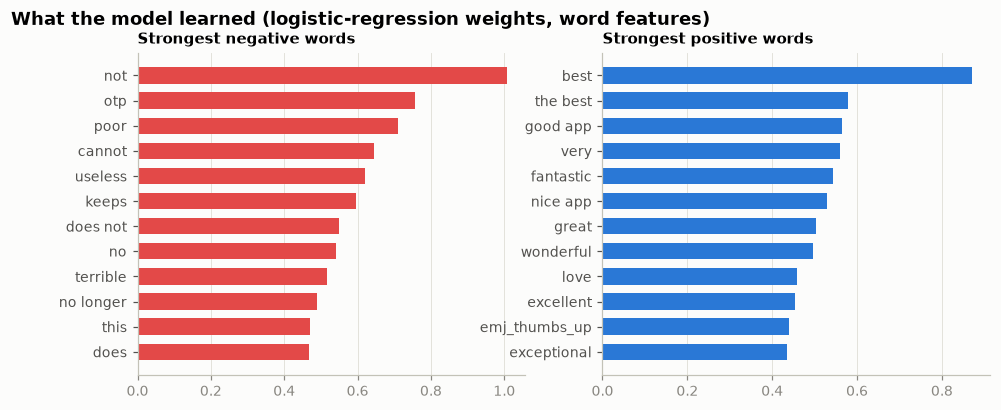

In [15]:
def word_features(pipe, n=12):
    tf = top_features(pipe, n=400)
    keep = {}
    for cls, feats in tf.items():
        words = [(f.split("__", 1)[1], w) for f, w in feats if f.startswith("word__")]
        keep[cls] = words[:n]
    return keep

final_words = word_features(model)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, cls in zip(axes, ["negative", "positive"]):
    w = final_words[cls][::-1]
    ax.barh([a for a, _ in w], [b for _, b in w], color=viz.SENTIMENT_COLORS[cls], height=0.65)
    ax.set_title(f"Strongest {cls} words", fontsize=10); ax.grid(axis="y", visible=False)
fig.suptitle("What the model learned (logistic-regression weights, word features)", x=0.01, ha="left", fontweight="bold")
viz.save(fig, "05_top_words")
plt.show()

* Negation dominates the negative side: *not*, *cannot*, *does not*, *no*, *no longer*. "no longer" only exists
  because of rule 5 (*nolonger -> no longer*), and emj_thumbs_up only because emojis are converted to words, so these
  cleaning steps create useful features even where the overall score barely moves.
* "otp" is the second-strongest negative word. OTP problems are so common in complaints that the word itself
  carries a negative prior; a neutral mention ("I received the OTP") is pulled towards negative. Aspect *terms* can carry
  sentiment of their own, an effect that shows up again in the error analysis below ("neutral use of complaint-heavy words").

In [16]:
# shortcut check: retrain without brand masking
m_unmasked = make_pipeline_for(*BEST).set_params(**best_params).fit(texts["no brand masking (rule 7)"][train.index], train["label"])
brands = ["ecocash", "innbucks", "cbz", "econet", "touch", "super", "zb", "brandname"]
rank = {}
for cls, feats in top_features(m_unmasked, n=300).items():
    names = [f.split("__", 1)[1] for f, _ in feats if f.startswith("word__")]
    rank[cls] = {b: names.index(b) + 1 for b in brands if b in names}
pd.DataFrame(rank).rename_axis("brand word").astype(object).fillna("not in top 300")

,negative,neutral,positive
brand word,,,
cbz,57.0,not in top 300,not in top 300
super,not in top 300,not in top 300,21.0


Without masking, brand words enter the model's top features: "super" (from *Super App*) becomes the
21st strongest positive word, and "cbz" a negative one. The model is partly learning *which app* a review is
about rather than *what it says*. "super" is the dangerous one: it would push every EcoCash Super App review towards
positive and inflate exactly the old-vs-new comparison in notebook 07. Masking costs 0.003 CV macro-F1 (well inside
one standard deviation) and removes the bias. With masking, the strongest words are about *what happened*.

## 6. Error analysis (40 random errors on the unseen brands, read by hand)

Forty misclassified unseen-brand reviews were drawn at random and each was read and put into one category. The annotations are stored in
`data/processed/error_analysis_manual.csv`.

In [17]:
# manually annotated errors; check they are still misclassified
manual = pd.read_csv("data/processed/error_analysis_manual.csv", encoding="utf-8-sig")
errors = reviews.merge(manual, on="reviewId")
print(f"{(errors['pred'] != errors['label']).sum()} of the {len(errors)} annotated reviews are still misclassified "
      f"by the current model")
labels_ = {"label_noise": "Stars contradict the text (model is right)",
           "mixed_opinion": "Mixed opinion (praise + complaint/request)",
           "model_error": "Real model error",
           "uninformative_text": "Uninformative / noisy text",
           "positive_in_negative_words": "Praise written with negative words",
           "domain_words_biased": "Neutral use of complaint-heavy words"}
summary = errors["category"].map(labels_).value_counts().to_frame("errors")
summary["share"] = (summary["errors"] / len(errors)).map("{:.0%}".format)
summary

39 of the 40 annotated reviews are still misclassified by the current model


,errors,share
category,,
Stars contradict the text (model is right),12,30%
Mixed opinion (praise + complaint/request),9,22%
Real model error,9,22%
Uninformative / noisy text,5,12%
Praise written with negative words,3,8%
Neutral use of complaint-heavy words,2,5%


In [18]:
errors.groupby("category").head(2)[["category", "score", "label", "pred", "content", "note"]]

,category,score,label,pred,content,note
0,label_noise,5,positive,negative,it's not logged in,"5 stars on ""it's not logged in"""
1,positive_in_negative_words,4,positive,negative,"the new updates are out of this world, from old to new, slow to fast","""from old to new, slow to fast"" is praise"
2,mixed_opinion,4,positive,neutral,It can a much better app if you could add NFC payments for smartphones or smartwatches.,NaN
3,mixed_opinion,4,positive,neutral,Seems like the block & unblock slider only unblock either way,NaN
4,label_noise,3,neutral,positive,nice 💯🙂,NaN
5,model_error,1,negative,neutral,why dont they give us the option to change which wallet is being checked the balance. it defaults to zig with no opt...,NaN
8,domain_words_biased,5,positive,negative,opening the application,NaN
13,uninformative_text,5,positive,negative,Abdisa Mohammad Zealand Zealand zero zeroes Zealand,NaN
14,model_error,1,negative,neutral,The app continue saying the account is locked before i could even use it,NaN
15,positive_in_negative_words,5,positive,negative,"One of the best, trouble free application to free up your money....can't do without it. Many unnecessary trips to th...","""trouble free"", ""can't do without it"", ""unnecessary trips avoided"""


About a third of the "errors" are label noise: the stars contradict the text and the model's prediction is
arguably correct (*5-star "Not open"*, *2-star "Cool"*). Another fifth are mixed reviews where a single label cannot be
right. The review-level scores above therefore underestimate the model, and a sentence-level, aspect-level
evaluation against human labels (notebook 06) is needed. Real errors involve hedged negation (*"not that user
friendly"*), factual complaints without emotional words (*"usage of the app attracts a charge"*), and praise phrased
negatively (*"trouble free"*, *"can't do without it"*).

## 7. Save the models

* `sentiment_eval.joblib`: trained on the train subset only, used for every evaluation (notebook 06)
* `sentiment_final.joblib`: same configuration retrained on all 6,206 reviews, used for the full-corpus analysis
  (notebook 07) and the interface. The final model is never evaluated on data it has seen; its expected performance is
  the evaluation model's.

In [19]:
joblib.dump(model, MODELS_DIR / "sentiment_eval.joblib")
final = make_pipeline_for(*BEST).set_params(**best_params).fit(reviews["clean"], reviews["label"])
joblib.dump(final, MODELS_DIR / "sentiment_final.joblib")
json.dump({"features": BEST[0], "classifier": BEST[1], "params": best_params,
           "cv_macro_f1": float(choice["cv_macro_f1"].iloc[0])},
          open(MODELS_DIR / "model_card.json", "w"), indent=2)
print("saved:", sorted(p.name for p in MODELS_DIR.glob("*.joblib")))

saved: ['sentiment_eval.joblib', 'sentiment_final.joblib']
